# Activity 7.04 – Visualizing the Top 30 Music YouTube Channels Using Seaborn's FacetGrid



### 01: Use pandas to read the `YouTube.csv` dataset located in the Datasets folder.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

mydata = pd.read_csv('YouTube.csv')
mydata.head()


,Channel,Subs (in millions),Views (in millions)
0,T-Series,123.0,94410
1,Canal KondZilla,54.5,27860
2,Zee Music Company,48.5,22689
3,Ed Sheeran,43.2,18905
4,EminemMusic,40.2,773


### 02: Access the data of each group in the column, convert this into a list, and assign this list to variables of each respective group.


In [2]:
subscribers = mydata['Subs (in millions)'].tolist()
views = mydata['Views (in millions)'].tolist()


### 03: Create a pandas DataFrame with the preceding data, using the data of each respective group.


In [3]:
data = pd.DataFrame({'Channel': mydata['Channel'].tolist(),
                     'Subscribers': subscribers,
                     'Views': views})
data.head()


,Channel,Subscribers,Views
0,T-Series,123.0,94410
1,Canal KondZilla,54.5,27860
2,Zee Music Company,48.5,22689
3,Ed Sheeran,43.2,18905
4,EminemMusic,40.2,773


### 04: Create a FacetGrid with two columns to visualize the data.

First melt the DataFrame into a long format with a `Type` column, then build a two-column FacetGrid that shows subscribers on the left and views on the right.


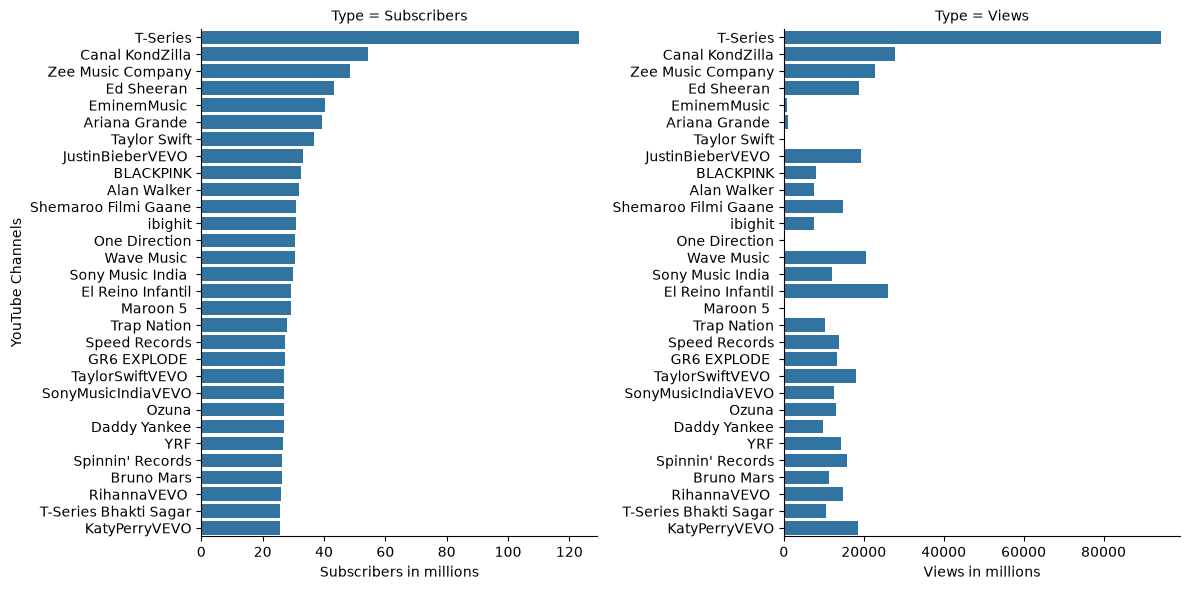

In [4]:
# Reshape into long format for FacetGrid
df = data.melt(id_vars='Channel', var_name='Type', value_name='Count')

# Two-column FacetGrid with a horizontal bar plot per column;
# the default category order keeps the top channel (T-Series) at the top
g = sns.FacetGrid(df, col='Type', sharex=False, sharey=False)
g.figure.set_size_inches(12, 6)
g.map(sns.barplot, 'Count', 'Channel', order=df['Channel'].unique())

# Axis labels and ticks matching the expected output
g.axes.flat[0].set_ylabel('YouTube Channels')
g.axes.flat[0].set_xlabel('Subscribers in millions')
g.axes.flat[1].set_xlabel('Views in millions')
g.axes.flat[0].set_xticks([0, 20, 40, 60, 80, 100, 120])
g.axes.flat[1].set_xticks([0, 20000, 40000, 60000, 80000])
plt.show()
